In [1]:
import random as rd
import pandas as pd
import math

Variant = 21
rd.seed(Variant)

set_operations = ['-','+','*','/']
set_operands = ['a', 'b', 'c']
count_operations = rd.randint(3,5)

expression = set_operands[rd.randint(0,len(set_operands)-1)]
for i in range(count_operations):
    current_operation = set_operations[rd.randint(0,len(set_operations)-1)]
    current_operand = set_operands[rd.randint(0,len(set_operands)-1)]
    expression = "(" + expression + current_operation + current_operand + ")"
expression

'(((b/c)*b)+b)'

In [ ]:
format ELF64 ; Обозначение формата архитектуры 64x

public _start ; Точка запуска программы
public input ; Точка обработки переданных аргументов
public first ; Первая подпрограмма - задание ЛР 1
public second ; Вторая подпрограмма - задание ЛР 2
public handler ; Обработчик, после input. Запускает подпрограммы ЛР1/2
public str_to_int ; Преобразует строку в число
public finally ; Подпрограмма выхода из программы

section '.data' writable ; Секция data
	error_0 db "ERROR 0. Zero arguments", 0xA 
	l_error_0 = $-error_0

section '.bss' writable ; Секция bss
	buffer db 512 dup (?) ; Хранение ASCII номер символа
	buffer_2 dq 3 dup (?) ; Хранение a, b, c чисел в целочисленном формате

section '.text' executable ; Секция кода	

_start:	
	pop rcx ; Сюда запишем кол-во переданных аргументов
	jmp input ; Заполняется буффер. rcx - кол-во (основных) аргументов. 
	
input:
        xor rax, rax
        xor rbx, rbx
	xor rdx, rdx
        inc rax ; Для пропуска аргумента в виде названия самой программы
	cmp rax, rcx ; Проверяем, что аргументов (основных) не 0
	je .error_0 ; Если аргументов нету, то выводим сообщение об ошибки и завершаем программу.

	mov rsi, [rsp + 8] ; Первый аргумент (основной) - номер программы (номер задания ЛР)
	mov dl, [rsi]

	jmp handler

.error_0: ; Если кол-во аргументов (основных) равно 0
                mov rdx, l_error_0 ; Загружаем длину
                mov rsi, error_0 ; Адрес памяти начала сообщения
                mov rax, 1
                mov rdi, 1

                syscall

                jmp exit
	
handler:
        cmp dl, '1' ; Проверяем на вызов 1 программы
        je first
	cmp dl, '2' ; Проверяем на вызов 2 программы
	je second
	jmp exit	

second:
	;Вспомним, что buffer_2[0] = a, buffer_2[1] = b, buffer_2[2] = c
	;Само выражение: (((b/c)*b)+b
	xor rcx, rcx
	.iter:
		mov rsi, [rsp + 16 + 8*rcx] ; Начинаем с второго аргумента и так ещё 2 следующих преобразуем
		call str_to_int ; Преобразуем строку в число
		inc rcx
		cmp rcx, 3
		jne .iter

	mov rbx, [buffer_2 + 8]
	mov rcx, [buffer_2 + 16]

	mov rax, [buffer_2 + 8]
	xor rdx, rdx
	div rcx
	mul rbx
	add rax, rbx

	mov [buffer + 511], 0xA


	xor rdx, rdx
	mov rcx, 510
	mov rbx, 10
		
	.iter1:
		xor rdx, rdx
		cmp rax, 0
		je .next
		div rbx
		add dl, '0'
		mov [buffer + rcx] , dl
		dec rcx
		jne .iter1
	.next:
		mov rcx, 511
		call finally
	
		jmp exit

	
str_to_int: 
	push rcx
	; В rsi необходимо передать указатель на строку
	; rax - аккумулятор числа
	xor rax, rax
	.iter:
		cmp byte [rsi], 0
		je .next
		mov dl, byte [rsi]
		sub dl, '0'
		push rdx
		mov rdx, 10
		mul rdx
		pop rdx
		add rax, rdx
		inc rsi ; Следующая цифра

		jmp .iter

	.next:	
		mov [buffer_2 + 8 * rcx], rax 
		pop rcx
		ret

first:
	mov [buffer + 3], 0xA ; Записываем в конец массива перенос сразу, чтобы было удобнее
	mov rsi, [rsp + 16] ; Второй аргумент должен быть символом
	mov [buffer + 2], 0xA
	push rax
	push rbx
	push rcx
	push rdx
	push rsi

	xor rax, rax
	mov rbx, 2 ; Будем в конец записывать
	mov al, [rsi] ;  Символ по ASCII
	mov rcx, 10 ; Делитель
	.iter1:
		xor rdx, rdx
		div rcx ; В rax хранится целое, после деления, rdx - остаток
      		add dl, '0'
		mov [buffer+rbx], dl ;Записываем в конец буфера, чтобы не писать программу для инверсии
		dec rbx
      		cmp rax, 0
		jne .iter1 


	mov rcx, 4
	call finally

	pop rsi
        pop rdx
        pop rcx
        pop rbx
        pop rax

	jmp exit

finally:
	mov rdx, rcx
	mov rsi, buffer
	mov rax, 1
	mov rdi, 1	
	syscall

	ret		

section '.exit' executable
exit:
    mov rax, 60
    xor rdi, rdi
    syscall

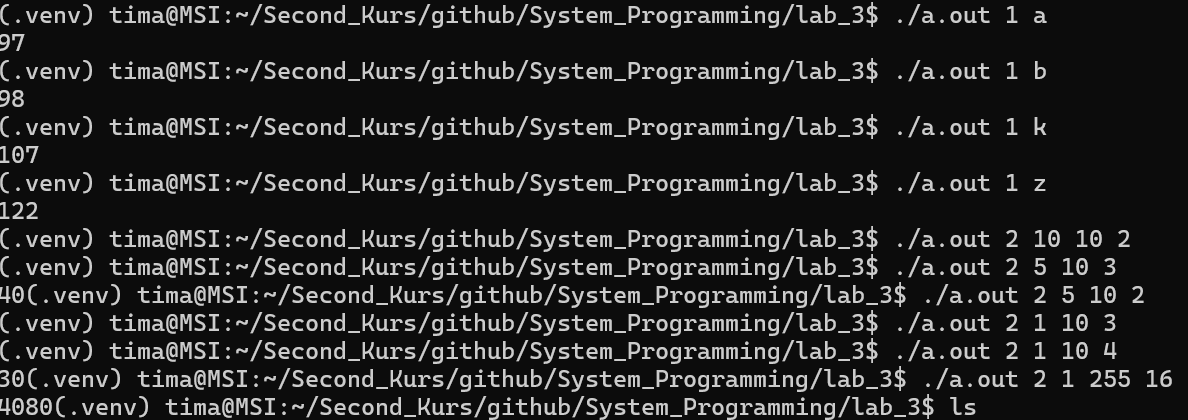

In [ ]:
#include <stdio.h>
#include <stdlib.h>

int main(int argc, char *argv[]) {

    int a = atol(argv[1]);
    int b = atol(argv[2]);
    int c = atol(argv[3]);

    int result = (((b / c) * b) + b);

    printf("%d\n", result);
    return 0;
}

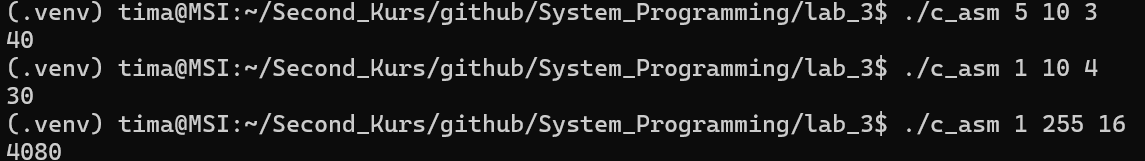